# Label distributions across languages in the clean HPLT collection

**Questions:**

1. How do the Qwen3.8-27B topic and format label distributions differ between languages in
   the `clean_random` collection, and which languages stand out?
2. Compared with English, how are other languages different? A configurable handful of
   languages is compared in detail.
3. What do the two labels WebOrganizer doesn't have, *Other* and *Bad example*, reveal
   about the languages' data?

**Data:**

- **Label shares of every language:** `results/datasets/{topic,format}/hplt-finetune/label_counts.tsv`,
  written by `scripts/model_training/create_datasets.py`. Per split, source, language and
  label it holds the documents, the documents with that top label and the summed
  probability. The notebook uses the `clean_random` rows of all three splits together,
  so every language contributes its whole labelled clean sample (25,000 documents; 16 small
  languages have fewer). No sampling, and it reads in seconds.
- **Other and Bad example documents:** `results/statistics/other_bad_examples/<language>.jsonl`,
  written by `scripts/data_analysis/extract_top_label_documents.py` (the same files as
  `inspect_top_label_documents.ipynb`): every *training* document of a language whose top
  topic or top format label is Other or Bad example, with the top two labels of both label
  types, the URL and the text. Only the `clean_random` documents are used here.

**Measures:**

- A label's **share** in a language is its mean probability over the language's documents,
  in percent. The **top share** is the percentage of documents whose most probable label
  it is. They are close when Qwen is confident; they differ for labels that collect
  probability as a second choice (Other does).
- The **distance** between two languages' distributions is the Jensen-Shannon divergence
  (JSD) in bits: 0 for identical distributions, 1 for distributions with no label in
  common (defined in `hplt_label_distributions.ipynb`, section 4). Across all clean
  languages, a distance from English of about 0.02 bits is "very like English" and 0.14
  is the median language.
- The **mean of languages** averages the shares over languages, so every language counts
  equally whatever its size.

**How to use it:** set `COMPARE_LANGUAGES` (and, if wanted, `REFERENCE`) in the
*Parameters* cell and run all cells. Language names are the dataset's (lower case,
underscores, e.g. `simplified_chinese`, `norwegian_bokmål`). Section 6 reads the
extracted documents of `INSPECT_LANGUAGES`; a language without a file there stops the
notebook with the extraction command, or with `EXTRACT_MISSING = True` the notebook runs
it (about 10 minutes over sshfs for any number of languages, since it scans the
training split). The notebook writes nothing else.

The related notebook `hplt_label_distributions.ipynb` compares the clean, noisy and poor
collections and checks whether a few websites dominate a language (domain
concentration); this one stays inside the clean collection and measures against English.

## Setup

Imports, the repository root, the chart style and two helpers.

- **Colours:** topic is blue and format orange wherever both appear (the first two slots
  of a colour-blind-checked palette). Differences from English use a diverging scale:
  blue where a language has less of a label than English, red where it has more, grey
  for about the same. Highlighted languages are blue, the rest grey.
- **`js_bits`** is the Jensen-Shannon divergence in bits.
- **`annotate_without_overlap`** names points in a chart without names covering each
  other or other points; a name that doesn't fit is left out (the tables list everything).

In [26]:
from __future__ import annotations

import html
import json
import subprocess
import sys
from collections import Counter
from pathlib import Path
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

# Find the repository root whether Jupyter runs from the root or from notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)

SURFACE, TEXT, MUTED, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#b5b4ae"
TYPE_COLORS = {"topic": "#2a78d6", "format": "#eb6834"}
HIGHLIGHT = "#2a78d6"
# Diverging scale for differences: blue (less than the reference), grey (same), red (more).
DIVERGING = LinearSegmentedColormap.from_list("difference", ["#256abf", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
    "legend.frameon": False,
})


def js_bits(p: np.ndarray, q: np.ndarray) -> float:
    """Jensen-Shannon divergence of two probability vectors, in bits."""
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        mask = a > 0
        return float(np.sum(a[mask] * np.log2(a[mask] / b[mask])))

    return (kl(p, m) + kl(q, m)) / 2


def annotate_without_overlap(ax: plt.Axes, points: list[tuple[float, float, str]], fontsize: int = 10) -> None:
    """Name points in order of importance, each beside its point where it overlaps nothing.

    Args:
        ax: Axes holding the scatter markers.
        points: (x, y, name) in data coordinates, the most important first.
        fontsize: Font size of the names.
    """
    fig = ax.figure
    fig.canvas.draw()
    to_pixels = fig.dpi / 72
    char_width, height = 0.6 * fontsize * to_pixels, 1.2 * fontsize * to_pixels
    frame = ax.get_window_extent()
    taken = []
    for collection in ax.collections:  # every scatter marker, as a small box
        for x, y in ax.transData.transform(collection.get_offsets()):
            taken.append((x - 4, y - 4, x + 4, y + 4))
    for x, y, text in points:
        px, py = ax.transData.transform((x, y))
        width = char_width * len(text)
        for dx, dy in ((6, 3), (6, -3 - height), (-6 - width, 3), (-6 - width, -3 - height)):
            box = (px + dx, py + dy, px + dx + width, py + dy + height)
            inside = frame.x0 <= box[0] and box[2] <= frame.x1 and frame.y0 <= box[1] and box[3] <= frame.y1
            clear = not any(box[0] < b[2] and b[0] < box[2] and box[1] < b[3] and b[1] < box[3]
                            for b in taken if not (b[0] < px < b[2] and b[1] < py < b[3]))
            if inside and clear:
                taken.append(box)
                ax.annotate(text, (x, y), xytext=(dx / to_pixels, dy / to_pixels), textcoords="offset points",
                            fontsize=fontsize, color=TEXT, va="bottom", ha="left")
                break

## Parameters

Everything a typical rerun changes is set here.

- `REFERENCE`: the language the others are compared against (English).
- `COMPARE_LANGUAGES`: the handful compared with the reference in detail (section 4) and
  highlighted in the charts. The default mixes a close neighbour (German), the project's
  own Finnish, and four large languages in other scripts, one of which (Simplified
  Chinese) has an unusual amount of Bad example.
- `INSPECT_LANGUAGES`: the languages whose Other and Bad example documents are read
  (section 6): the reference, the comparison languages, and six languages that
  stand out on Other or Bad example in section 5.1.
- `MIN_DIFFERENCE`: in percentage points; labels that no comparison language differs
  from the reference on by at least this much are left out of the section 4 heatmaps.
- `SNIPPETS_PER_GROUP`, `SNIPPET_CHARS`: the overview of Other and Bad example
  documents in section 6.5.
- `CARD_LANGUAGE`, `CARD_LABEL_TYPE`, `CARD_LABEL`, `CARD_SAMPLE_SIZE`, `SEED`,
  `PREVIEW_CHARS`: the random sample of full documents in section 6.6.
- `EXTRACT_MISSING`: run the extraction for `INSPECT_LANGUAGES` without a file (about
  10 minutes).

In [2]:
REFERENCE = "english"
COMPARE_LANGUAGES = ["german", "finnish", "russian", "simplified_chinese", "arabic", "hindi"]
INSPECT_LANGUAGES = [REFERENCE, *COMPARE_LANGUAGES, "latin", "thai", "serbian_latin", "tok_pisin", "pangasinan", "awadhi"]
SOURCE = "clean_random"
LABEL_TYPES = ("topic", "format")
SPECIAL_LABELS = ("Other", "Bad example")
MIN_DIFFERENCE = 1.5

SNIPPETS_PER_GROUP = 3
SNIPPET_CHARS = 160
CARD_LANGUAGE = "simplified_chinese"
CARD_LABEL_TYPE = "topic"
CARD_LABEL = "Bad example"
CARD_SAMPLE_SIZE = 8
SEED = 0
PREVIEW_CHARS = 1200
EXTRACT_MISSING = False

DATASETS = {label_type: ROOT / f"results/datasets/{label_type}/hplt-finetune" for label_type in LABEL_TYPES}
EXTRACTED_DIR = ROOT / "results/statistics/other_bad_examples"
EXTRACT_SCRIPT = ROOT / "scripts/data_analysis/extract_top_label_documents.py"

if REFERENCE in COMPARE_LANGUAGES:
    raise ValueError(f"REFERENCE {REFERENCE!r} is also in COMPARE_LANGUAGES")
if CARD_LABEL_TYPE not in LABEL_TYPES or CARD_LABEL not in SPECIAL_LABELS:
    raise ValueError(f"CARD_LABEL_TYPE must be one of {LABEL_TYPES} and CARD_LABEL one of {SPECIAL_LABELS}")

## 1. Read the label shares

`label_counts.tsv` has one row per split, source, language and label. The `clean_random`
rows of the three splits are added up per language and label, and two checks guard the
result: every language has every label exactly once per split, and the top-label counts
and probabilities add up to the document count (a probability sum may be off by rounding
only).

`shares` has one row per label type, language and label, with `documents`, `share` and
`top_share` (both in percent). `wide[label_type]` is the same as a language × label table
of shares.

In [3]:
def read_label_names(dataset: Path) -> list[str]:
    """Label names of a dataset, in its label order."""
    names = json.loads((dataset / "labels.json").read_text(encoding="utf-8"))["label_names"]
    if not names:
        raise ValueError(f"No label names in {dataset / 'labels.json'}")
    return list(names)


def read_shares(label_type: str) -> pd.DataFrame:
    """Shares of every label in every language of SOURCE, from label_counts.tsv."""
    path = DATASETS[label_type] / "label_counts.tsv"
    counts = pd.read_csv(path, sep="\t")
    counts = counts[counts["source"] == SOURCE]
    if counts.empty:
        raise ValueError(f"No {SOURCE} rows in {path}")
    names = LABELS[label_type]
    per_split = counts.groupby(["split", "language"])["label"].agg(lambda labels: sorted(labels) == sorted(names))
    if not per_split.all():
        raise ValueError(f"{path}: some split and language don't have every label once: {per_split[~per_split].index.tolist()[:5]}")
    totals = counts.groupby(["language", "label"], as_index=False)[["documents", "top_label_documents", "probability_sum"]].sum()
    check = totals.groupby("language").agg(documents=("documents", "first"), top=("top_label_documents", "sum"),
                                           probability=("probability_sum", "sum"))
    if (check["documents"] != check["top"]).any() or ((check["documents"] - check["probability"]).abs() > 0.01).any():
        raise ValueError(f"{path}: top-label counts or probabilities don't add up to the document counts")
    totals["share"] = 100 * totals["probability_sum"] / totals["documents"]
    totals["top_share"] = 100 * totals["top_label_documents"] / totals["documents"]
    totals.insert(0, "label_type", label_type)
    return totals[["label_type", "language", "label", "documents", "share", "top_share"]]


LABELS = {label_type: read_label_names(path) for label_type, path in DATASETS.items()}
shares = pd.concat([read_shares(label_type) for label_type in LABEL_TYPES], ignore_index=True)
wide = {label_type: shares[shares["label_type"] == label_type].pivot(index="language", columns="label", values="share")[LABELS[label_type]]
        for label_type in LABEL_TYPES}
top_wide = {label_type: shares[shares["label_type"] == label_type].pivot(index="language", columns="label", values="top_share")[LABELS[label_type]]
            for label_type in LABEL_TYPES}
documents = shares.groupby("language")["documents"].first()

LANGUAGES = sorted(documents.index)
for language in [REFERENCE, *COMPARE_LANGUAGES, *INSPECT_LANGUAGES]:
    if language not in documents.index:
        raise ValueError(f"{language!r} is not a {SOURCE} language; choose from: {', '.join(LANGUAGES)}")
if set(wide["topic"].index) != set(wide["format"].index):
    raise ValueError("The topic and format tables have different languages")

print(f"{len(LANGUAGES)} languages, {documents.sum():,} {SOURCE} documents")
small = documents[documents < 20000].sort_values()
print(f"{len(small)} languages with fewer than 20,000 documents:")
display(small.rename("documents").to_frame().T)

128 languages, 2,917,166 clean_random documents
16 languages with fewer than 20,000 documents:


language,magahi,banjar_arabic,kabuverdianu,pangasinan,tibetan,awadhi,banjar_latin,tok_pisin,ligurian,chhattisgarhi,waray,balinese,minangkabau,sicilian,silesian,latgalian
documents,524,1200,3020,3478,3723,5168,5578,5661,6746,7721,9076,10982,13019,13543,13616,14111


**Sampling noise is small:** with 25,000 documents per language, a 10% share has a
standard error of about 0.2 percentage points, a 1% share about 0.07. Documents from the
same website aren't independent, so the real uncertainty is somewhat larger, but the
differences discussed below are mostly several points. The small languages above are
noisier: Magahi's 524 documents give a 10% share a standard error of 1.3 points.

## 2. English against the other languages

English is the usual reference, but it isn't a typical language of the clean collection.
The chart shows each label's share in English (blue) and its mean over all languages
(grey), joined by a line; labels are sorted by the larger of the two. The table gives the
numbers, with the median language as well, since a few extreme languages (e.g. Tok Pisin,
70% Religion) pull the mean.

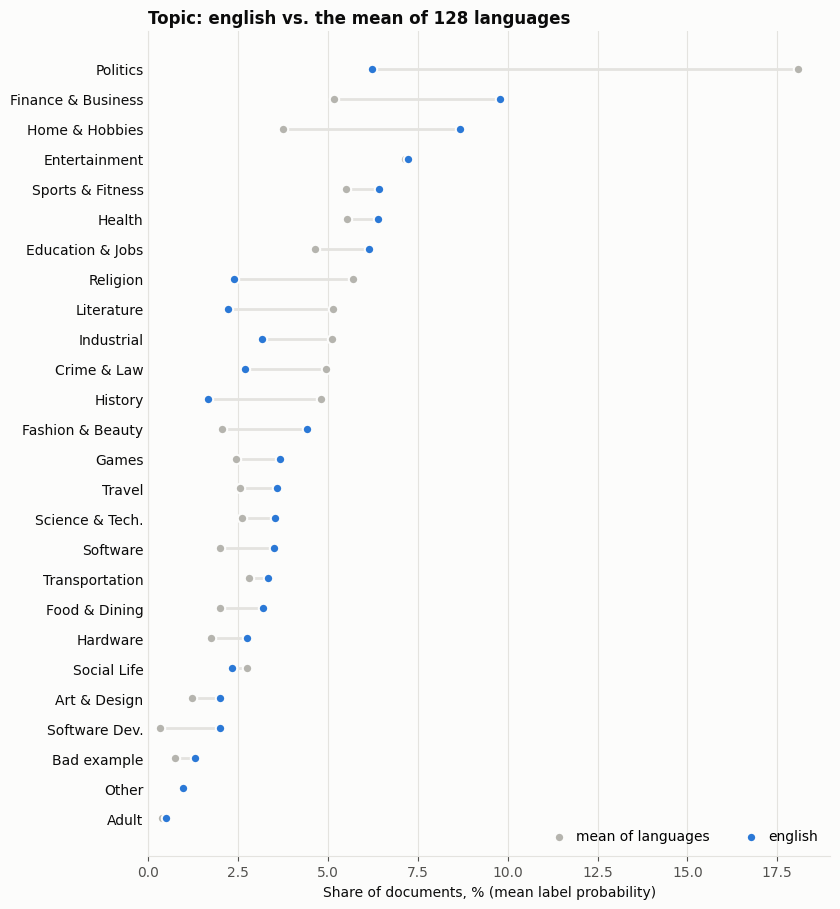

,english,mean of languages,median language,english − mean,languages above english
label,,,,,
Politics,6.21,18.08,15.39,-11.87,109
Religion,2.38,5.69,3.42,-3.31,82
History,1.65,4.79,2.31,-3.14,95
Literature,2.21,5.14,2.51,-2.93,79
Crime & Law,2.69,4.94,3.75,-2.25,82
Industrial,3.17,5.12,3.48,-1.95,75
Social Life,2.34,2.74,2.03,-0.41,51
Other,0.97,0.94,0.87,0.03,50
Entertainment,7.23,7.14,6.45,0.09,46


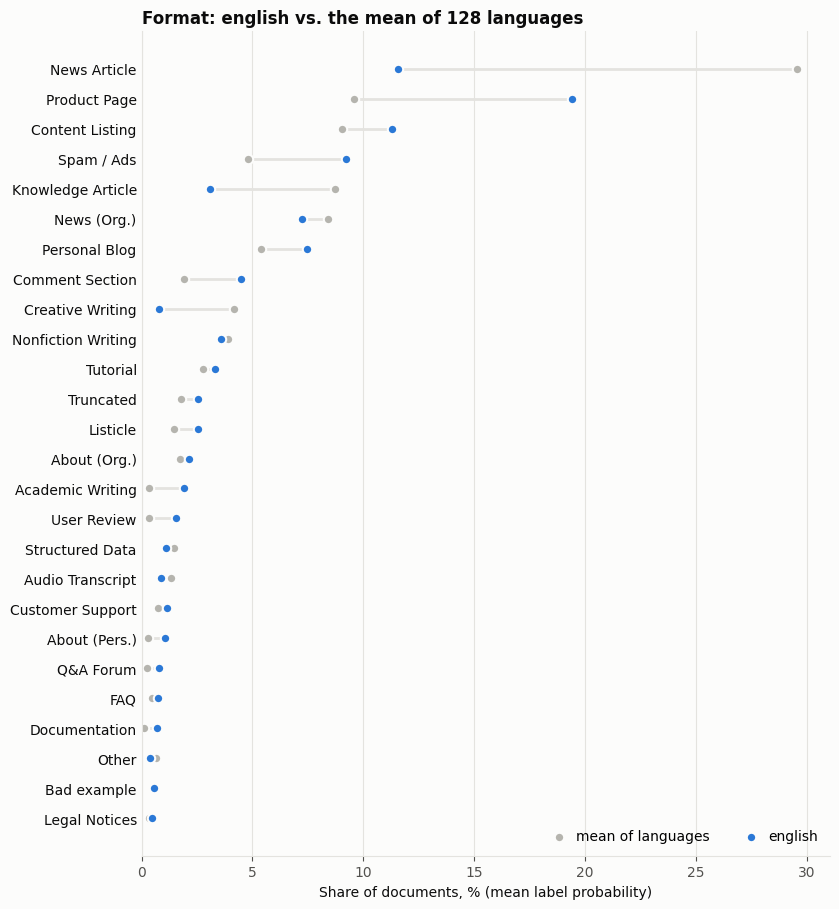

,english,mean of languages,median language,english − mean,languages above english
label,,,,,
News Article,11.56,29.58,24.70,-18.02,97
Knowledge Article,3.10,8.74,4.66,-5.64,110
Creative Writing,0.77,4.16,1.36,-3.39,97
News (Org.),7.24,8.42,7.25,-1.19,64
Audio Transcript,0.86,1.34,1.01,-0.48,75
Structured Data,1.12,1.44,0.67,-0.32,32
Nonfiction Writing,3.59,3.90,3.43,-0.30,60
Other,0.40,0.64,0.33,-0.24,44
Bad example,0.55,0.51,0.23,0.04,14


In [4]:
def reference_vs_languages(label_type: str) -> pd.DataFrame:
    """The reference's shares next to the mean and median language's."""
    table = wide[label_type]
    result = pd.DataFrame({
        REFERENCE: table.loc[REFERENCE],
        "mean of languages": table.mean(),
        "median language": table.median(),
    })
    result[f"{REFERENCE} − mean"] = result[REFERENCE] - result["mean of languages"]
    result[f"languages above {REFERENCE}"] = (table > table.loc[REFERENCE]).sum()
    return result


def plot_reference_vs_languages(label_type: str) -> None:
    table = reference_vs_languages(label_type)
    order = table[[REFERENCE, "mean of languages"]].max(axis=1).sort_values().index
    fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(order) + 1.4))
    y = np.arange(len(order))
    ax.hlines(y, table.loc[order, [REFERENCE, "mean of languages"]].min(axis=1),
              table.loc[order, [REFERENCE, "mean of languages"]].max(axis=1), color=GRID, linewidth=2, zorder=1)
    ax.scatter(table.loc[order, "mean of languages"], y, s=46, color=NEUTRAL, edgecolor=SURFACE, linewidth=1.5,
               zorder=2, label="mean of languages")
    ax.scatter(table.loc[order, REFERENCE], y, s=46, color=HIGHLIGHT, edgecolor=SURFACE, linewidth=1.5,
               zorder=3, label=REFERENCE)
    ax.set_yticks(y, order)
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)
    ax.set_xlabel("Share of documents, % (mean label probability)")
    ax.set_title(f"{label_type.capitalize()}: {REFERENCE} vs. the mean of {len(LANGUAGES)} languages", loc="left")
    ax.legend(loc="lower right", ncols=2, handletextpad=0.2)
    plt.tight_layout()
    plt.show()


for label_type in LABEL_TYPES:
    plot_reference_vs_languages(label_type)
    display(reference_vs_languages(label_type).sort_values(f"{REFERENCE} − mean").round(2))

## 3. Which languages stand out

### 3.1 Distance from English and from the other languages

For every language, two distances per label type:

- `js_reference`: its JSD from the reference (English);
- `js_mean`: its JSD from the mean of all languages, i.e. how unusual it is regardless of
  English.

`more` and `less` list the three labels the language has most above and below the
reference, in percentage points (only differences of at least 3 points). The tables
show the 20 languages furthest from the reference, then the 10 closest.

In [5]:
def describe(difference: pd.Series, sign: int, count: int = 3, minimum: float = 3.0) -> str:
    """The labels with the largest difference of one sign, as 'Label +12, ...'."""
    picked = (sign * difference).sort_values(ascending=False).head(count)
    return ", ".join(f"{label} {difference[label]:+.0f}" for label, value in picked.items() if value >= minimum)


distance_rows = []
for label_type in LABEL_TYPES:
    table = wide[label_type]
    reference, mean = table.loc[REFERENCE], table.mean()
    for language, row in table.iterrows():
        difference = row - reference
        distance_rows.append({
            "label_type": label_type, "language": language, "documents": documents[language],
            "js_reference": js_bits(row.to_numpy(), reference.to_numpy()),
            "js_mean": js_bits(row.to_numpy(), mean.to_numpy()),
            "more": describe(difference, +1), "less": describe(difference, -1),
        })
distances = pd.DataFrame(distance_rows)

for label_type in LABEL_TYPES:
    part = distances[(distances["label_type"] == label_type) & (distances["language"] != REFERENCE)]
    part = part.sort_values("js_reference", ascending=False)
    display(Markdown(f"**{label_type.capitalize()}:** median distance from {REFERENCE} "
                     f"{part['js_reference'].median():.3f} bits; {REFERENCE}'s distance from the mean of languages "
                     f"{distances.query('label_type == @label_type and language == @REFERENCE')['js_mean'].iloc[0]:.3f} "
                     f"(median language {distances.query('label_type == @label_type')['js_mean'].median():.3f})."))
    columns = ["language", "documents", "js_reference", "js_mean", "more", "less"]
    display(part.head(20)[columns].round(3).reset_index(drop=True))
    display(part.tail(10).iloc[::-1][columns].round(3).reset_index(drop=True))

**Topic:** median distance from english 0.142 bits; english's distance from the mean of languages 0.070 (median language 0.073).

,language,documents,js_reference,js_mean,more,less
0,tok_pisin,5661,0.570,0.424,"Religion +70, Politics +4","Finance & Business -9, Home & Hobbies -8, Entertainment -6"
1,pangasinan,3478,0.568,0.435,"Religion +67, Literature +4","Finance & Business -9, Home & Hobbies -8, Sports & Fitness -6"
2,ligurian,6746,0.464,0.348,"Literature +40, History +23, Religion +4","Finance & Business -9, Home & Hobbies -8, Education & Jobs -6"
3,magahi,524,0.405,0.214,"Politics +25, Literature +22, Industrial +4","Finance & Business -9, Home & Hobbies -8, Entertainment -6"
4,sardinian,25000,0.377,0.241,"Literature +44, Politics +9, History +7","Finance & Business -9, Home & Hobbies -8, Health -5"
5,awadhi,5168,0.353,0.152,"Politics +22, Religion +17, Crime & Law +8","Finance & Business -9, Home & Hobbies -8, Entertainment -6"
6,lao,25000,0.349,0.208,"Politics +48, Industrial +11","Home & Hobbies -8, Entertainment -7, Sports & Fitness -5"
7,limburgish,25000,0.346,0.267,"Entertainment +24, History +16, Literature +10","Finance & Business -9, Home & Hobbies -8, Health -6"
8,balinese,10982,0.342,0.214,"Literature +19, History +18, Religion +16","Finance & Business -9, Home & Hobbies -8, Health -4"
9,occitan,25000,0.342,0.197,"History +24, Literature +17, Politics +14","Finance & Business -9, Home & Hobbies -8, Health -5"


,language,documents,js_reference,js_mean,more,less
0,german,25000,0.010,0.068,,
1,french,25000,0.012,0.061,,
2,polish,25000,0.014,0.075,Home & Hobbies +3,
3,czech,25000,0.016,0.083,Home & Hobbies +4,
4,estonian,25000,0.017,0.052,"Politics +3, Health +3",
5,norwegian_bokmål,25000,0.018,0.069,,
6,finnish,25000,0.018,0.073,,
7,latvian,25000,0.018,0.050,Politics +3,
8,dutch,25000,0.019,0.093,Home & Hobbies +4,
9,hungarian,25000,0.020,0.046,"Health +3, Politics +3",Finance & Business -4


**Format:** median distance from english 0.161 bits; english's distance from the mean of languages 0.088 (median language 0.098).

,language,documents,js_reference,js_mean,more,less
0,ligurian,6746,0.613,0.474,"Creative Writing +45, Knowledge Article +34","Product Page -19, News Article -11, Content Listing -10"
1,magahi,524,0.555,0.312,"News Article +42, Creative Writing +29, Nonfiction Writing +3","Product Page -19, Content Listing -11, Spam / Ads -9"
2,sicilian,13543,0.503,0.380,"Knowledge Article +43, Creative Writing +28","Product Page -18, News Article -10, Spam / Ads -8"
3,banjar_latin,5578,0.487,0.359,"Knowledge Article +41, Creative Writing +28","Product Page -19, News Article -8, Spam / Ads -7"
4,balinese,10982,0.478,0.338,"Knowledge Article +40, Creative Writing +19, Structured Data +8","Product Page -19, Content Listing -9, Spam / Ads -8"
5,awadhi,5168,0.467,0.211,"News Article +43, Creative Writing +13, Knowledge Article +8","Product Page -19, Spam / Ads -9, Content Listing -7"
6,minangkabau,13019,0.451,0.335,"Knowledge Article +39, Creative Writing +20","Product Page -19, News Article -10, News (Org.) -7"
7,odia,25000,0.445,0.226,News Article +69,"Product Page -18, Spam / Ads -9, Content Listing -8"
8,nepali,25000,0.429,0.222,News Article +67,"Product Page -18, Spam / Ads -9, Personal Blog -6"
9,lombard,25000,0.420,0.262,"Knowledge Article +48, Creative Writing +9, News (Org.) +4","Product Page -19, Spam / Ads -9, Content Listing -7"


,language,documents,js_reference,js_mean,more,less
0,french,25000,0.013,0.085,Product Page +5,
1,german,25000,0.022,0.094,"Product Page +5, News (Org.) +4",
2,polish,25000,0.022,0.077,Content Listing +6,
3,czech,25000,0.023,0.076,"Product Page +5, Content Listing +3",Personal Blog -3
4,norwegian_bokmål,25000,0.023,0.061,"News Article +5, News (Org.) +4","Content Listing -4, Spam / Ads -3"
5,hungarian,25000,0.027,0.039,"News Article +10, Content Listing +3",
6,dutch,25000,0.028,0.102,"Product Page +8, News (Org.) +4",Spam / Ads -3
7,slovak,25000,0.031,0.080,"Product Page +8, News Article +5",Personal Blog -4
8,hebrew,25000,0.031,0.051,"News Article +5, Knowledge Article +4",Spam / Ads -5
9,russian,25000,0.032,0.045,News Article +10,Personal Blog -4


### 3.2 Chart: every language's distance from English, topic against format

Each dot is a language: x is its topic distance from the reference, y its format
distance, both on linear axes from zero. The 15 languages furthest from the reference
(topic and format distances added) are named where there is room. The languages close to
the reference crowd into the lower-left corner, so the right-hand panel enlarges that
corner (the box) and names the 10 closest. A language
far out on one axis is usually far out on the other, because the same pages (Bible
sites, Wikipedia stubs, spam) drive both.

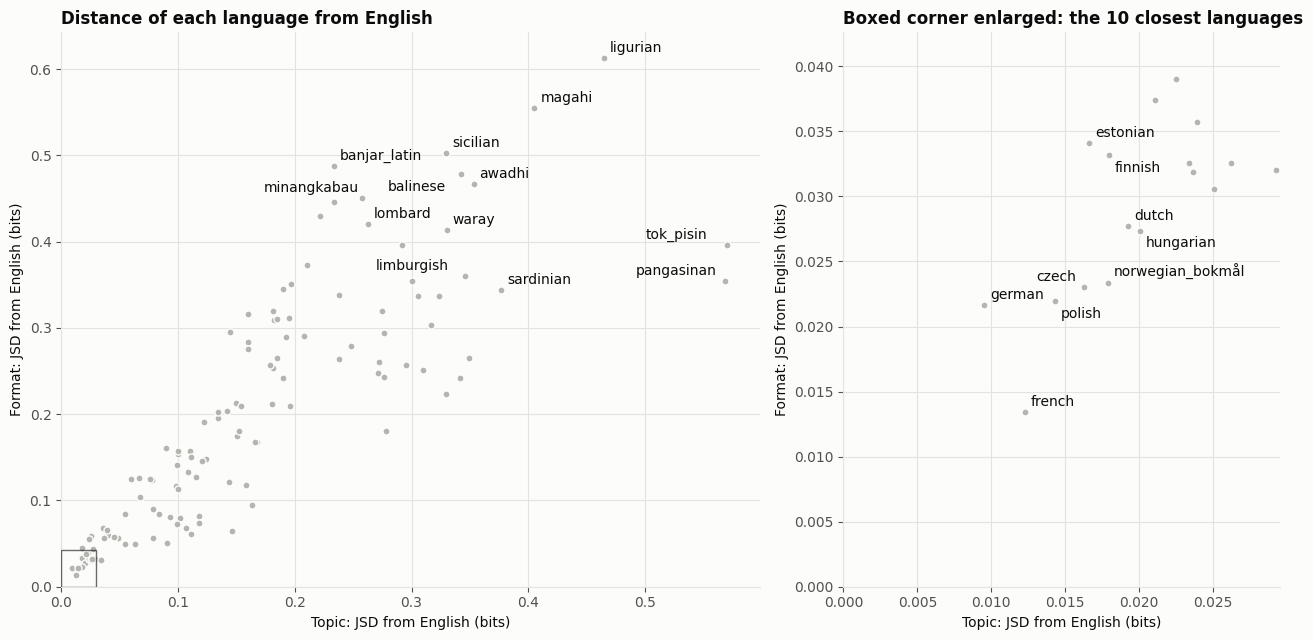

Spearman correlation of topic and format distance: 0.92


In [27]:
def plot_distance_scatter() -> None:
    both = distances.pivot(index="language", columns="label_type", values="js_reference").drop(index=REFERENCE)
    far = both.sum(axis=1).sort_values(ascending=False).head(15).index
    near = both.sum(axis=1).sort_values().head(10).index
    # Second panel: the lower-left corner of the main chart enlarged so the closest languages
    # can be named. Its range is set by the closest languages, with a margin.
    fig, (ax, zoom) = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
    for panel in (ax, zoom):
        panel.scatter(both["topic"], both["format"], s=26, color=NEUTRAL, edgecolor=SURFACE, linewidth=1, zorder=2)
        panel.set_xlabel(f"Topic: JSD from {REFERENCE.capitalize()} (bits)")
        panel.set_ylabel(f"Format: JSD from {REFERENCE.capitalize()} (bits)")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    zoom.set_xlim(0, 1.25 * both.loc[near, "topic"].max())
    zoom.set_ylim(0, 1.25 * both.loc[near, "format"].max())
    ax.set_title(f"Distance of each language from {REFERENCE.capitalize()}", loc="left")
    zoom.set_title(f"Boxed corner enlarged: the {len(near)} closest languages", loc="left")
    plt.tight_layout()
    x_max, y_max = zoom.get_xlim()[1], zoom.get_ylim()[1]
    # A box without connector lines, which would cross the data.
    ax.add_patch(plt.Rectangle((0, 0), x_max, y_max, fill=False, edgecolor=TEXT, alpha=0.6, linewidth=1, zorder=3))
    annotate_without_overlap(ax, [(both.loc[language, "topic"], both.loc[language, "format"], language)
                                  for language in far])
    annotate_without_overlap(zoom, [(both.loc[language, "topic"], both.loc[language, "format"], language)
                                    for language in near])
    plt.savefig(f"../results/figures/distance_scatter_vs_{REFERENCE}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Spearman correlation of topic and format distance: {both['topic'].corr(both['format'], method='spearman'):.2f}")


plot_distance_scatter()

### 3.3 How languages typically differ from English

The same question per label instead of per language: for every label, the spread of
(language's share − reference's share) over all languages. The dot is the median
language, the thick line the middle half of the languages (25th to 75th percentile) and
the thin line the middle 80% (10th to 90th). A dot right of zero means most languages
have more of the label than English. Labels are sorted by the median difference.

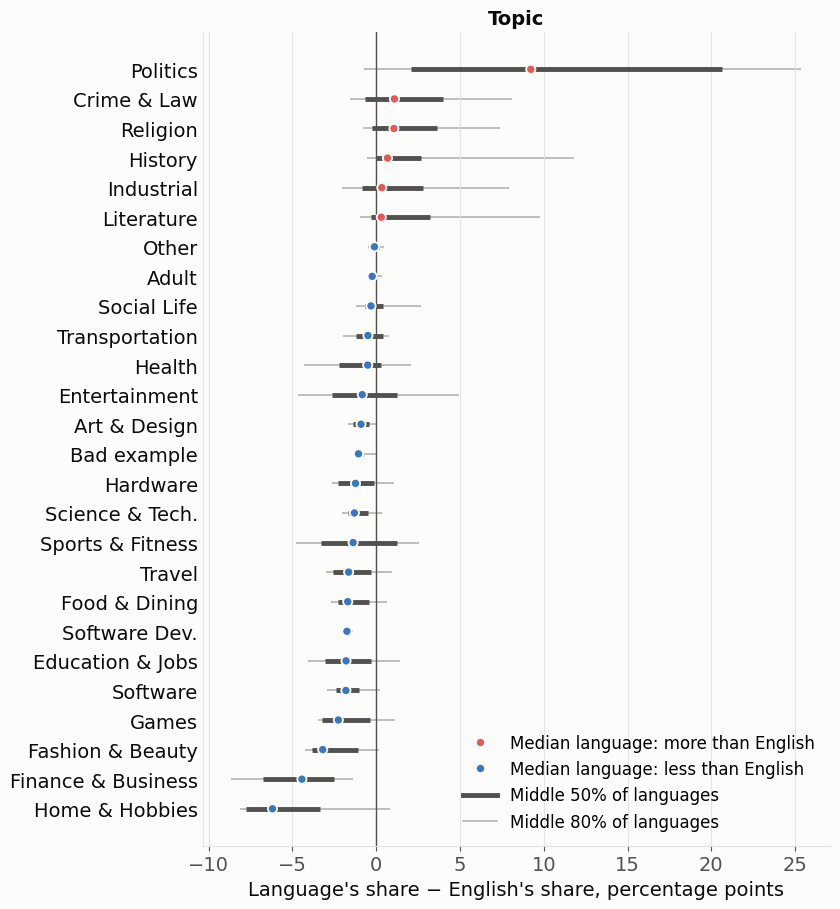

,p10,p25,median,p75,p90,languages above english,largest,largest_difference
label,,,,,,,,
Home & Hobbies,-8.11,-7.76,-6.19,-3.37,0.81,16,danish,6.38
Finance & Business,-8.64,-6.73,-4.43,-2.53,-1.39,2,korean,3.53
Fashion & Beauty,-4.22,-3.83,-3.19,-1.11,0.17,17,japanese,3.77
Games,-3.46,-3.22,-2.26,-0.35,1.15,25,thai,28.47
Software,-2.91,-2.42,-1.81,-1.02,0.21,16,māori,4.38
Education & Jobs,-4.10,-3.08,-1.80,-0.30,1.42,24,welsh,6.39
Software Dev.,-1.95,-1.86,-1.75,-1.56,-1.36,0,latin,-0.81
Food & Dining,-2.71,-2.28,-1.70,-0.41,0.66,28,cantonese,7.25
Travel,-3.01,-2.59,-1.64,-0.34,0.92,27,xhosa,22.83


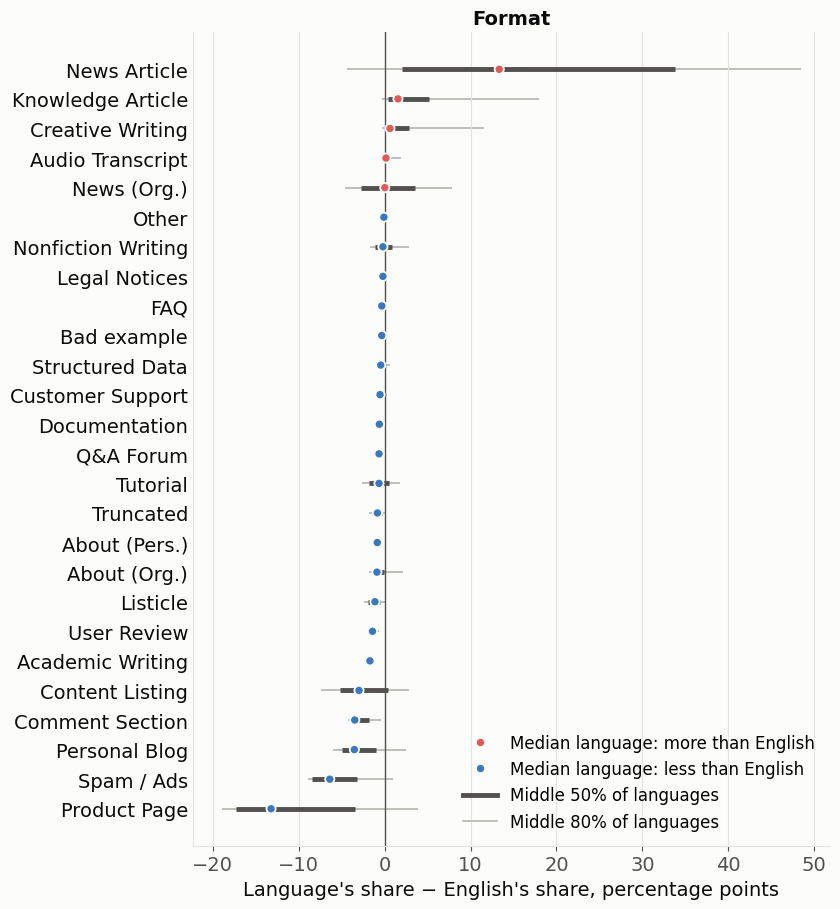

,p10,p25,median,p75,p90,languages above english,largest,largest_difference
label,,,,,,,,
Product Page,-18.93,-17.34,-13.20,-3.46,3.86,22,danish,10.89
Spam / Ads,-8.87,-8.43,-6.37,-3.22,1.01,18,thai,37.11
Personal Blog,-5.95,-4.92,-3.52,-0.99,2.53,24,cantonese,24.47
Comment Section,-4.21,-3.95,-3.47,-1.77,-0.41,8,yiddish,12.65
Content Listing,-7.39,-5.21,-2.98,0.34,2.80,34,khmer,20.16
Academic Writing,-1.86,-1.80,-1.70,-1.53,-1.19,2,tibetan,2.00
User Review,-1.55,-1.51,-1.40,-1.20,-0.62,3,cantonese,1.57
Listicle,-2.37,-1.87,-1.12,-0.57,0.09,15,cantonese,2.65
About (Org.),-1.84,-1.47,-0.89,-0.01,2.12,31,lao,5.73


In [29]:
def difference_spread(label_type: str) -> pd.DataFrame:
    table = wide[label_type].drop(index=REFERENCE)
    difference = table - wide[label_type].loc[REFERENCE]
    spread = difference.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).T
    spread.columns = ["p10", "p25", "median", "p75", "p90"]
    spread[f"languages above {REFERENCE}"] = (difference > 0).sum()
    spread["largest"] = difference.idxmax()
    spread["largest_difference"] = difference.max()
    return spread.sort_values("median")


def plot_difference_spread(label_type: str) -> None:
    spread = difference_spread(label_type)
    fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(spread) + 1.4))
    y = np.arange(len(spread))
    ax.hlines(y, spread["p10"], spread["p90"], color=NEUTRAL, linewidth=1.2, zorder=1)
    ax.hlines(y, spread["p25"], spread["p75"], color=MUTED, linewidth=3.5, zorder=2)
    colors = [DIVERGING(0.05) if value < 0 else DIVERGING(0.95) for value in spread["median"]]
    ax.scatter(spread["median"], y, s=44, color=colors, edgecolor=SURFACE, linewidth=1.3, zorder=3)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(y, spread.index)
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"Language's share − {REFERENCE.capitalize()}'s share, percentage points")
    ax.set_title(f"{label_type.capitalize()}")
    reference = REFERENCE.capitalize()
    dot_style = dict(marker="o", linestyle="none", markersize=np.sqrt(44), markeredgecolor=SURFACE, markeredgewidth=1.3)
    handles = [
        Line2D([], [], color=DIVERGING(0.95), label=f"Median language: more than {reference}", **dot_style),
        Line2D([], [], color=DIVERGING(0.05), label=f"Median language: less than {reference}", **dot_style),
        Line2D([], [], color=MUTED, linewidth=3.5, label="Middle 50% of languages"),
        Line2D([], [], color=NEUTRAL, linewidth=1.2, label="Middle 80% of languages"),
    ]
    ax.legend(handles=handles, loc="lower right", fontsize = 12)
    # Increase font size of all text
    for item in ([ax.title, ax.xaxis.label] + ax.get_xticklabels() + ax.get_yticklabels() + [ax.yaxis.label]):
            item.set_fontsize(14)
    plt.tight_layout()
    plt.savefig(f"../results/figures/{label_type}_label_differences_vs_english.png", dpi=300, bbox_inches="tight")
    plt.show()


for label_type in LABEL_TYPES:
    plot_difference_spread(label_type)
    display(difference_spread(label_type).round(2))

### 3.4 Chart: the most unusual languages, label by label

A heatmap of the 25 languages furthest from the mean of languages (`js_mean`, rows,
most unusual first) against the labels: each cell is the language's share minus the
*reference's* share, in percentage points, so it shows both what makes these languages
unusual and how that compares with English. Red is more than the reference, blue less;
cells of at least 10 points carry their value. The scale is cut at ±40.

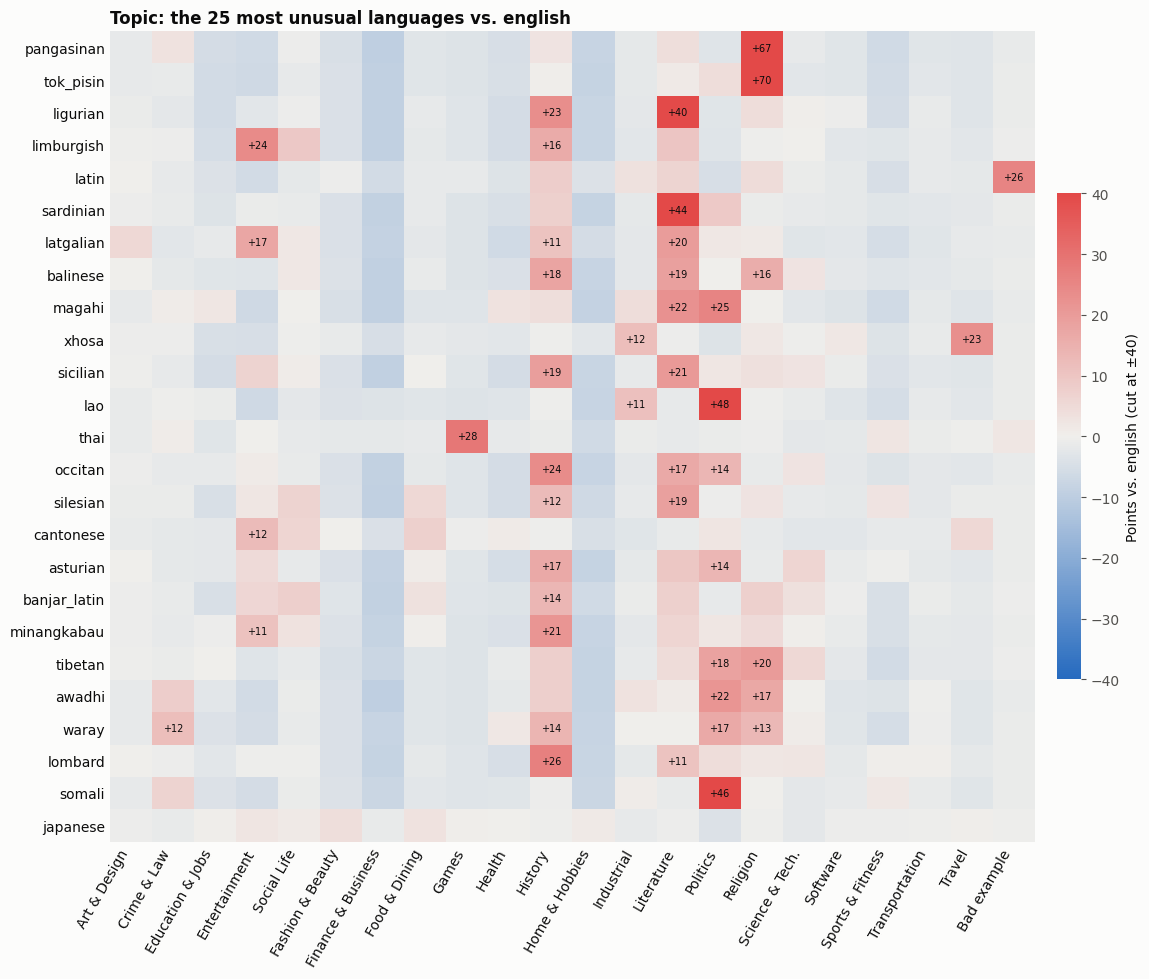

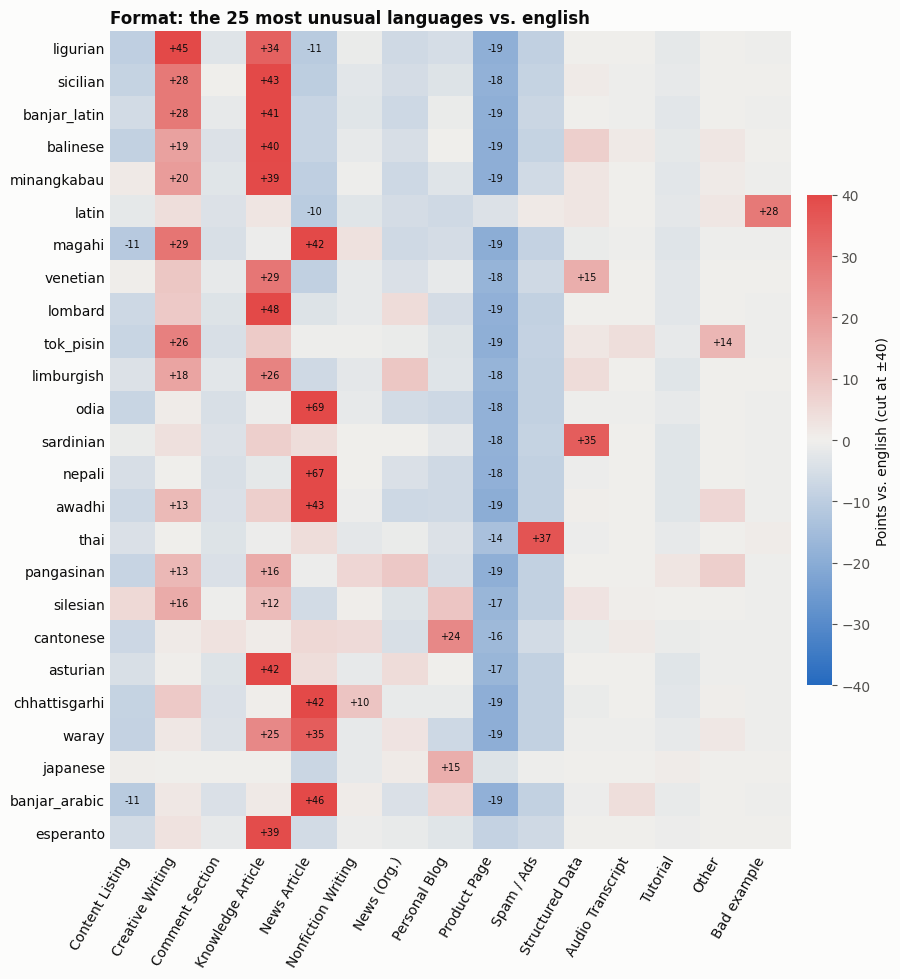

In [8]:
def plot_difference_heatmap(matrix: pd.DataFrame, title: str, limit: float = 40.0, annotate_from: float = 10.0,
                            transpose: bool = False) -> None:
    """A diverging heatmap of differences in percentage points."""
    if transpose:
        matrix = matrix.T
    fig, ax = plt.subplots(figsize=(0.42 * matrix.shape[1] + 3.2, 0.3 * matrix.shape[0] + 2.4))
    image = ax.imshow(matrix.clip(-limit, limit), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
    for (i, j), value in np.ndenumerate(matrix.to_numpy()):
        if abs(value) >= annotate_from:
            ax.text(j, i, f"{value:+.0f}" if abs(value) >= 10 else f"{value:+.1f}", ha="center", va="center",
                    fontsize=7, color=TEXT)
    ax.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=60, ha="right")
    ax.set_yticks(range(matrix.shape[0]), matrix.index)
    ax.tick_params(colors=TEXT, length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    bar = fig.colorbar(image, ax=ax, shrink=0.6, pad=0.02)
    bar.set_label(f"Points vs. {REFERENCE} (cut at ±{limit:.0f})")
    bar.outline.set_visible(False)
    ax.set_title(title, loc="left")
    plt.tight_layout()
    plt.show()


for label_type in LABEL_TYPES:
    unusual = distances[distances["label_type"] == label_type].nlargest(25, "js_mean")["language"]
    matrix = wide[label_type].loc[unusual] - wide[label_type].loc[REFERENCE]
    matrix = matrix.loc[:, matrix.abs().max() >= 3]
    plot_difference_heatmap(matrix, f"{label_type.capitalize()}: the 25 most unusual languages vs. {REFERENCE}")

## 4. The chosen languages against English

`COMPARE_LANGUAGES` side by side with the reference. First the distances, then for each
label type a heatmap with one column per language: each cell is the language's share
minus the reference's, in percentage points, with values of at least 1 point written in
the cell. Labels that no chosen language differs on by `MIN_DIFFERENCE` points or more
are left out, and labels are sorted by their mean difference. The table after each
heatmap has the shares themselves.

In [9]:
summary = distances[distances["language"].isin(COMPARE_LANGUAGES)].pivot(
    index="language", columns="label_type", values=["js_reference", "js_mean"]).loc[COMPARE_LANGUAGES]
summary.columns = [f"{measure} ({label_type})" for measure, label_type in summary.columns]
for label_type in LABEL_TYPES:
    ranks = distances[(distances["label_type"] == label_type) & (distances["language"] != REFERENCE)].set_index("language")["js_reference"].rank()
    summary[f"rank from {REFERENCE} ({label_type})"] = ranks.loc[COMPARE_LANGUAGES].astype(int)
summary.insert(0, "documents", documents.loc[COMPARE_LANGUAGES])
display(Markdown(f"Distances in bits. The rank is out of {len(LANGUAGES) - 1} languages, 1 = closest to {REFERENCE}."))
display(summary.round(3))

Distances in bits. The rank is out of 127 languages, 1 = closest to english.

,documents,js_reference (format),js_reference (topic),js_mean (format),js_mean (topic),rank from english (topic),rank from english (format)
language,,,,,,,
german,25000,0.022,0.010,0.094,0.068,1,2
finnish,25000,0.033,0.018,0.108,0.073,7,14
russian,25000,0.032,0.024,0.045,0.050,14,10
simplified_chinese,25000,0.141,0.099,0.143,0.123,45,57
arabic,25000,0.117,0.098,0.054,0.032,44,48
hindi,25000,0.283,0.160,0.115,0.067,75,93


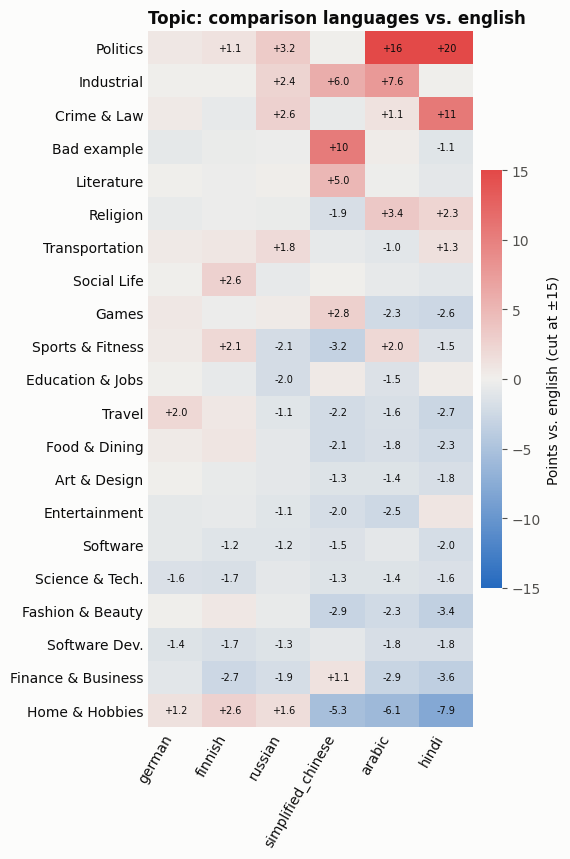

language,english,german,finnish,russian,simplified_chinese,arabic,hindi,mean of languages
label,,,,,,,,
Politics,6.2,6.8,7.3,9.4,6.3,22.2,26.5,18.1
Industrial,3.2,3.1,3.3,5.6,9.1,10.8,3.2,5.1
Crime & Law,2.7,3.2,2.0,5.3,2.1,3.8,13.3,4.9
Bad example,1.3,0.6,0.9,1.0,11.6,1.6,0.2,0.7
Literature,2.2,2.2,1.9,2.4,7.2,2.0,1.4,5.1
Religion,2.4,1.9,2.1,2.0,0.5,5.8,4.7,5.7
Transportation,3.3,3.8,4.0,5.1,2.7,2.3,4.6,2.8
Social Life,2.3,2.3,4.9,1.6,2.3,1.7,1.4,2.7
Games,3.7,4.3,3.3,4.1,6.4,1.4,1.0,2.4


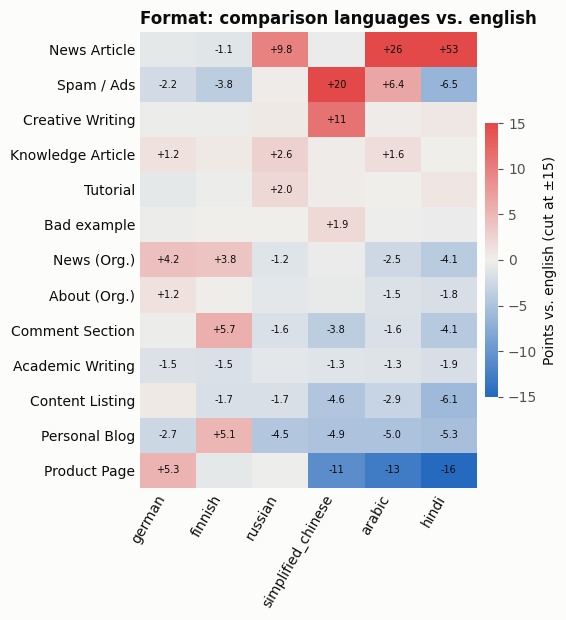

language,english,german,finnish,russian,simplified_chinese,arabic,hindi,mean of languages
label,,,,,,,,
News Article,11.6,10.9,10.5,21.4,11.2,37.2,64.8,29.6
Spam / Ads,9.2,7.1,5.4,9.6,29.1,15.7,2.7,4.8
Creative Writing,0.8,0.5,0.4,1.3,12.0,1.0,1.4,4.2
Knowledge Article,3.1,4.3,3.7,5.7,3.4,4.7,3.1,8.7
Tutorial,3.3,2.6,3.0,5.4,3.6,3.3,4.1,2.8
Bad example,0.6,0.3,0.6,0.5,2.5,0.4,0.2,0.5
News (Org.),7.2,11.4,11.1,6.0,6.9,4.8,3.1,8.4
About (Org.),2.1,3.3,2.3,1.2,1.6,0.6,0.4,1.7
Comment Section,4.5,4.2,10.2,2.9,0.6,2.9,0.3,1.9


In [10]:
def comparison_table(label_type: str) -> pd.DataFrame:
    table = wide[label_type].loc[[REFERENCE, *COMPARE_LANGUAGES]].T
    table["mean of languages"] = wide[label_type].mean()
    return table


for label_type in LABEL_TYPES:
    table = comparison_table(label_type)
    difference = table[COMPARE_LANGUAGES].sub(table[REFERENCE], axis=0)
    shown = difference[difference.abs().max(axis=1) >= MIN_DIFFERENCE]
    shown = shown.loc[shown.mean(axis=1).sort_values(ascending=False).index]
    plot_difference_heatmap(shown, f"{label_type.capitalize()}: comparison languages vs. {REFERENCE}", limit=15.0,
                            annotate_from=1.0)
    display(table.loc[shown.index.tolist() + [label for label in table.index if label not in shown.index]].round(1))

## 5. Other and Bad example across all languages

### 5.1 Ranking

Four (label type, label) pairs: topic Other, topic Bad example, format Other, format Bad
example. For each, the chart shows every language's **top share** (percentage of
documents whose most probable label it is) on a logarithmic axis, one dot per language.
The reference is blue with a ring, the comparison languages blue, and the five highest
languages of each row are named where there is room. Languages with no such document
at all sit at the left edge. The table lists the 10 highest of each.

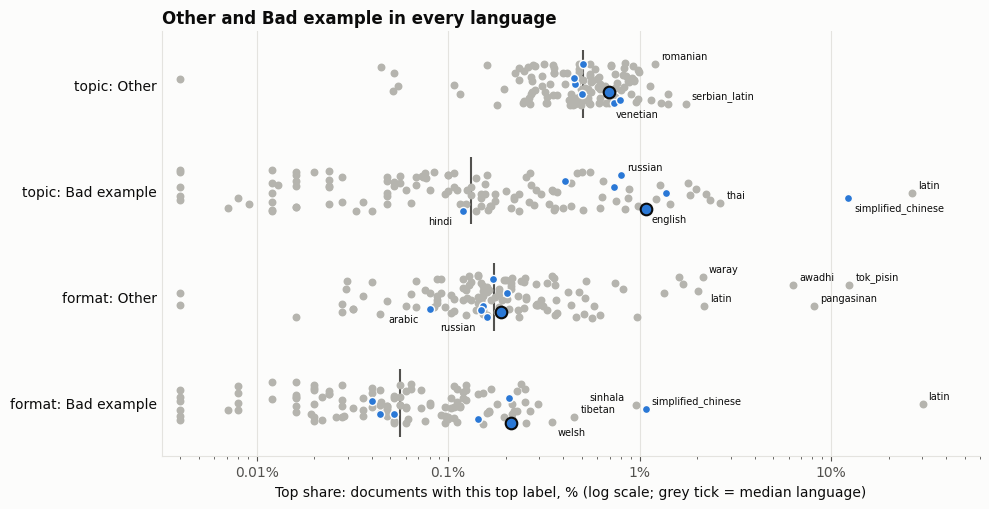

Top shares in percent, highest first:

,topic: Other,topic: Bad example,format: Other,format: Bad example
1,serbian_latin 1.7,latin 26.6,tok_pisin 12.5,latin 30.1
2,venetian 1.4,simplified_chinese 12.3,pangasinan 8.1,simplified_chinese 1.1
3,tatar 1.4,thai 2.6,awadhi 6.3,sinhala 1.0
4,macedonian 1.3,korean 2.3,latin 2.2,tibetan 0.5
5,romanian 1.2,mongolian 2.2,waray 2.1,welsh 0.3
6,bosnian 1.1,slovak 2.0,balinese 2.0,sicilian 0.3
7,bulgarian 1.1,traditional_chinese 1.8,minangkabau 1.7,irish 0.3
8,latvian 1.0,vietnamese 1.8,ilocano 1.6,telugu 0.3
9,khmer 1.0,swedish 1.4,cebuano 1.3,limburgish 0.3
10,turkish 1.0,arabic 1.4,chhattisgarhi 1.0,venetian 0.3


Median language and the reference:

,top_share,share,english top_share,english rank (1 = highest)
pair,,,,
topic: Other,0.51,0.87,0.70,36
topic: Bad example,0.13,0.25,1.08,13
format: Other,0.17,0.33,0.19,57
format: Bad example,0.06,0.23,0.21,18


In [11]:
special = shares[shares["label"].isin(SPECIAL_LABELS)].copy()
special["pair"] = special["label_type"] + ": " + special["label"]
PAIRS = [f"{label_type}: {label}" for label_type in LABEL_TYPES for label in SPECIAL_LABELS]


def plot_special_ranking() -> None:
    fig, ax = plt.subplots(figsize=(10, 5.2))
    rng = np.random.default_rng(0)  # fixed jitter, so reruns look the same
    floor = 0.004  # where languages with no such document are drawn on the log axis
    names = []
    for row, pair in enumerate(PAIRS):
        part = special[special["pair"] == pair].set_index("language")
        x = part["top_share"].clip(lower=floor)
        jitter = pd.Series(rng.uniform(-0.2, 0.2, len(part)), index=part.index)
        rest = [language for language in part.index if language != REFERENCE and language not in COMPARE_LANGUAGES]
        ax.scatter(x[rest], row + jitter[rest], s=22, color=NEUTRAL, zorder=2)
        ax.scatter(x[COMPARE_LANGUAGES], row + jitter[COMPARE_LANGUAGES], s=34, color=HIGHLIGHT, edgecolor=SURFACE,
                   linewidth=1, zorder=3)
        ax.scatter(x[[REFERENCE]], row + jitter[[REFERENCE]], s=70, color=HIGHLIGHT, edgecolor=TEXT, linewidth=1.5, zorder=4)
        ax.vlines(part["top_share"].median(), row - 0.32, row + 0.32, color=MUTED, linewidth=1.5, zorder=1)
        names.append((x[REFERENCE], row + jitter[REFERENCE], REFERENCE))
        names += [(x[language], row + jitter[language], language) for language in part["top_share"].nlargest(5).index]
        names += [(x[language], row + jitter[language], language) for language in COMPARE_LANGUAGES]
    ax.set_xscale("log")
    ax.set_xlim(floor * 0.8, 60)
    ax.set_xticks([0.01, 0.1, 1, 10], ["0.01%", "0.1%", "1%", "10%"])
    ax.set_yticks(range(len(PAIRS)), PAIRS)
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(len(PAIRS) - 0.5, -0.5)
    ax.set_xlabel("Top share: documents with this top label, % (log scale; grey tick = median language)")
    ax.set_title("Other and Bad example in every language", loc="left")
    plt.tight_layout()
    annotate_without_overlap(ax, list(dict.fromkeys(names)), fontsize=7)
    plt.show()


plot_special_ranking()
ranking = {}
for pair in PAIRS:
    part = special[special["pair"] == pair].nlargest(10, "top_share")
    ranking[pair] = [f"{row.language} {row.top_share:.1f}" for row in part.itertuples()]
ranking = pd.DataFrame(ranking, index=range(1, 11))
display(Markdown("Top shares in percent, highest first:"))
display(ranking)
medians = special.groupby("pair")[["top_share", "share"]].median().loc[PAIRS]
medians[REFERENCE + " top_share"] = special[special["language"] == REFERENCE].set_index("pair").loc[PAIRS, "top_share"]
medians[REFERENCE + " rank (1 = highest)"] = [
    int(special[special["pair"] == pair]["top_share"].rank(ascending=False, method="min")[
        special[special["pair"] == pair]["language"] == REFERENCE].iloc[0]) for pair in PAIRS]
display(Markdown("Median language and the reference:"))
display(medians.round(2))

### 5.2 Do topic and format agree on Bad example?

Topic and format were labelled in separate prompts, so they are two independent judgements
of the same page. If Bad example marks really broken pages, a language with much topic Bad
example should also have much format Bad example. Each dot is a language (log scales);
the reference (ringed) and the comparison languages are blue and named where there is
room, and so are the languages with the most of the label. The same is shown for Other, where agreement is not expected: an
"other" topic and an "other" format are different things.

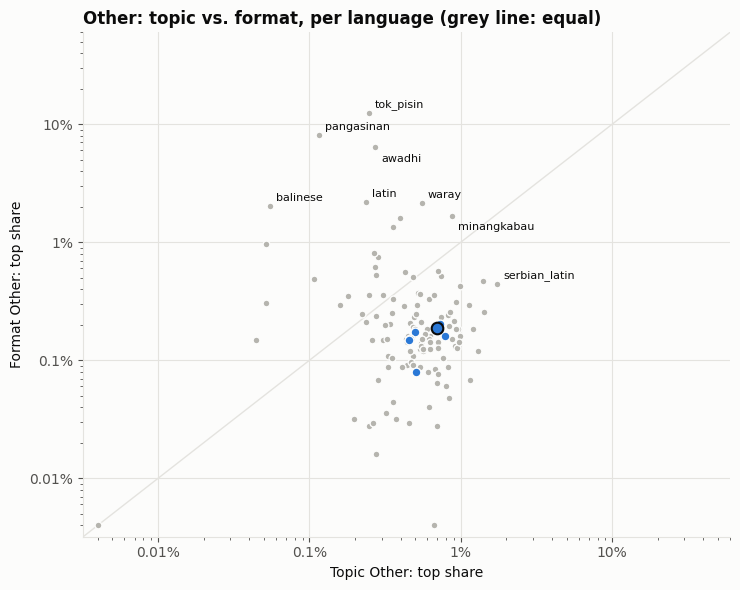

Spearman correlation over languages: -0.12


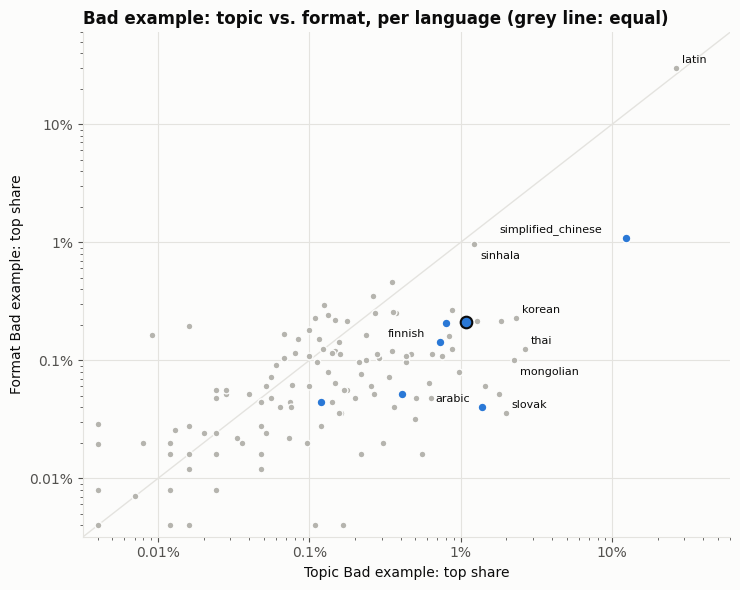

Spearman correlation over languages: 0.59


In [12]:
def plot_type_agreement(label: str) -> None:
    pivot = special[special["label"] == label].pivot(index="language", columns="label_type", values="top_share")
    floor = 0.004
    shown = pivot.clip(lower=floor)
    fig, ax = plt.subplots(figsize=(7.5, 6))
    rest = shown.drop(index=[REFERENCE, *COMPARE_LANGUAGES])
    ax.scatter(rest["topic"], rest["format"], s=24, color=NEUTRAL, edgecolor=SURFACE, linewidth=1, zorder=2)
    chosen = shown.loc[COMPARE_LANGUAGES]
    ax.scatter(chosen["topic"], chosen["format"], s=40, color=HIGHLIGHT, edgecolor=SURFACE, linewidth=1, zorder=3)
    ax.scatter(shown.loc[[REFERENCE], "topic"], shown.loc[[REFERENCE], "format"], s=70, color=HIGHLIGHT, edgecolor=TEXT,
               linewidth=1.5, zorder=4)
    limits = (floor * 0.8, 60)
    ax.plot(limits, limits, color=GRID, linewidth=1, zorder=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*limits)
    ax.set_ylim(*limits)
    ticks = [0.01, 0.1, 1, 10]
    ax.set_xticks(ticks, [f"{t:g}%" for t in ticks])
    ax.set_yticks(ticks, [f"{t:g}%" for t in ticks])
    ax.set_xlabel(f"Topic {label}: top share")
    ax.set_ylabel(f"Format {label}: top share")
    ax.set_title(f"{label}: topic vs. format, per language (grey line: equal)", loc="left")
    plt.tight_layout()
    order = [REFERENCE, *pivot.sum(axis=1).nlargest(8).index, *COMPARE_LANGUAGES]
    annotate_without_overlap(ax, [(shown.loc[language, "topic"], shown.loc[language, "format"], language)
                                  for language in dict.fromkeys(order)])
    plt.show()
    print(f"Spearman correlation over languages: {pivot['topic'].corr(pivot['format'], method='spearman'):.2f}")


for label in SPECIAL_LABELS:
    plot_type_agreement(label)

### 5.3 Other as a hedge

The share (mean probability) and the top share differ when Qwen gives a label
probability without choosing it. The ratio share / top share per language shows how much
of a label's probability is spread over pages that end up with another top label: about
1 means the label is used decisively, well above 1 that it is mostly a second choice. The
table has the median over languages, with the reference for comparison; the second
table compares with all ordinary labels together (their median ratio).

In [13]:
ratios = shares.assign(ratio=shares["share"] / shares["top_share"].where(shares["top_share"] > 0))
hedge = (ratios[ratios["label"].isin(SPECIAL_LABELS)]
         .groupby(["label_type", "label"])
         .agg(median_share=("share", "median"), median_top_share=("top_share", "median"),
              median_ratio=("ratio", "median")))
reference_ratio = ratios[(ratios["language"] == REFERENCE) & ratios["label"].isin(SPECIAL_LABELS)].set_index(["label_type", "label"])["ratio"]
hedge[f"{REFERENCE} ratio"] = reference_ratio
display(hedge.round(2))
ordinary = ratios[~ratios["label"].isin(SPECIAL_LABELS)].groupby("label_type")["ratio"].median()
display(Markdown("Median ratio of the ordinary labels: " + ", ".join(f"{t} {v:.2f}" for t, v in ordinary.items())))

median_share  median_top_share  median_ratio  english ratio
label_type label                                                                   
format     Bad example          0.23              0.06          3.06           2.60
           Other                0.33              0.17          1.85           2.13
topic      Bad example          0.25              0.13          1.68           1.21
           Other                0.87              0.51          1.65           1.40

Median ratio of the ordinary labels: format 1.02, topic 1.00

## 6. Reading the Other and Bad example documents

### 6.1 Load the extracted documents

The extracted files hold *training* documents of all three collections; only the
`SOURCE` ones are kept. As a check, their counts must equal the training-split top-label
counts in `label_counts.tsv`, so no document is missing or doubled.

In [14]:
missing = [language for language in INSPECT_LANGUAGES if not (EXTRACTED_DIR / f"{language}.jsonl").exists()]
command = [sys.executable, str(EXTRACT_SCRIPT), "--topic_dataset", str(DATASETS["topic"]),
           "--format_dataset", str(DATASETS["format"]), "--languages", *missing,
           "--labels", *SPECIAL_LABELS, "--output_dir", str(EXTRACTED_DIR)]
if missing:
    if not EXTRACT_MISSING:
        raise FileNotFoundError(
            f"No extracted documents for {missing}. Set EXTRACT_MISSING = True, or run from any directory:\n  "
            + " ".join(f"'{part}'" if " " in part else part for part in command))
    print("Extracting", ", ".join(missing), "(about 10 minutes) ...")
    subprocess.run(command, check=True)


def read_extracted(language: str) -> pd.DataFrame:
    path = EXTRACTED_DIR / f"{language}.jsonl"
    records = []
    with path.open(encoding="utf-8") as handle:
        for line in handle:
            record = json.loads(line)
            if record["source"] == SOURCE:
                records.append(record)
    if not records:
        raise ValueError(f"No {SOURCE} documents in {path}")
    return pd.json_normalize(records, sep="_")


docs = pd.concat([read_extracted(language) for language in INSPECT_LANGUAGES], ignore_index=True)
docs["chars"] = docs["text"].str.len()
docs["domain"] = [urlsplit(url).netloc.lower().removeprefix("www.") if url else "(no URL)" for url in docs["url"]]

# Check against the training-split counts of label_counts.tsv.
expected = []
for label_type in LABEL_TYPES:
    counts = pd.read_csv(DATASETS[label_type] / "label_counts.tsv", sep="\t")
    counts = counts[(counts["split"] == "train") & (counts["source"] == SOURCE) & counts["label"].isin(SPECIAL_LABELS)
                    & counts["language"].isin(INSPECT_LANGUAGES)]
    expected.append(counts.assign(label_type=label_type)[["language", "label_type", "label", "documents", "top_label_documents"]])
expected = pd.concat(expected).set_index(["language", "label_type", "label"])
found = pd.Series({(language, label_type, label): int(((docs["language"] == language) & (docs[f"{label_type}_top"] == label)).sum())
                   for language, label_type, label in expected.index})
if not found.equals(expected["top_label_documents"].astype(int).reindex(found.index)):
    bad = pd.DataFrame({"found": found, "expected": expected["top_label_documents"]})
    raise ValueError(f"Extracted documents don't match label_counts.tsv:\n{bad[bad['found'] != bad['expected']]}")
print(f"{len(docs):,} {SOURCE} training documents of {len(INSPECT_LANGUAGES)} languages; counts match label_counts.tsv")

overview = expected["top_label_documents"].unstack(["label_type", "label"]).loc[INSPECT_LANGUAGES]
overview.columns = [f"{t}: {l}" for t, l in overview.columns]
overview.insert(0, "training documents", expected["documents"].groupby("language").first().loc[INSPECT_LANGUAGES])
display(overview)

16,700 clean_random training documents of 13 languages; counts match label_counts.tsv


,training documents,topic: Other,topic: Bad example,format: Other,format: Bad example
language,,,,,
english,23510,163,255,45,48
german,23487,173,93,44,13
finnish,23443,118,166,40,35
russian,23491,187,188,39,50
simplified_chinese,23454,110,2870,32,246
arabic,23484,120,328,19,9
hindi,23460,106,26,35,11
latin,23507,54,6232,519,7050
thai,23511,84,628,24,30


### 6.2 Are they the same pages?

Per language and pair: how many documents have the label as top label, what share of
them also have the *other* label type's Other or Bad example, how confident Qwen is
(median probability of the label), and the median length in characters. A high overlap
between topic and format Bad example means both prompts saw a page that is broken in
itself; a low one means the label is used for different reasons in the two taxonomies.

In [15]:
rows = []
for language in INSPECT_LANGUAGES:
    part = docs[docs["language"] == language]
    for label_type in LABEL_TYPES:
        other_type = "format" if label_type == "topic" else "topic"
        for label in SPECIAL_LABELS:
            chosen = part[part[f"{label_type}_top"] == label]
            if chosen.empty:
                rows.append({"language": language, "pair": f"{label_type}: {label}", "documents": 0})
                continue
            rows.append({
                "language": language, "pair": f"{label_type}: {label}", "documents": len(chosen),
                f"also {other_type} Bad example, %": 100 * (chosen[f"{other_type}_top"] == "Bad example").mean(),
                f"also {other_type} Other, %": 100 * (chosen[f"{other_type}_top"] == "Other").mean(),
                "median probability": chosen[f"{label_type}_top_prob"].median(),
                "median chars": chosen["chars"].median(),
            })
overlap = pd.DataFrame(rows)
overlap = overlap.melt(id_vars=["language", "pair", "documents", "median probability", "median chars"],
                       var_name="measure", value_name="value").dropna(subset=["value"])
overlap = overlap.pivot_table(index=["pair", "language"], columns="measure", values="value", sort=False)
counts = pd.DataFrame(rows).set_index(["pair", "language"])[["documents", "median probability", "median chars"]]
display(counts.join(overlap).loc[PAIRS].round(2))

documents  median probability  median chars  also format Bad example, %  also format Other, %  also topic Bad example, %  also topic Other, %
pair                language                                                                                                                                                         
topic: Other        english                   163                0.62        1410.0                        0.00                  0.00                        NaN                  NaN
                    german                    173                0.58        1765.0                        0.00                  0.00                        NaN                  NaN
                    finnish                   118                0.55        1833.0                        0.00                  0.00                        NaN                  NaN
                    russian                   187                0.60        1904.0                        0.53                  0.00                        NaN                  NaN
                    simplified_chinese        110                0.52        1135.5                        0.00                  0.91                        NaN                  NaN
                    arabic                    120                0.59        1608.0                        0.00                  2.50                        NaN                  NaN
                    hindi                     106                0.51        1351.5                        0.00                  0.00                        NaN                  NaN
                    latin                      54                0.58        1260.0                        9.26                  1.85                        NaN                  NaN
                    thai                       84                0.50        2104.0                        0.00                  0.00                        NaN                  NaN
                    serbian_latin             403                0.59        1540.0                        0.00                  3.47                        NaN                  NaN
                    tok_pisin                  14                0.56        1836.0                        0.00                  0.00                        NaN                  NaN
                    pangasinan                  4                0.44        2405.0                        0.00                  0.00                        NaN                  NaN
                    awadhi                     14                0.51        1258.5                        0.00                  0.00                        NaN                  NaN
topic: Bad example  english                   255                0.78        3880.0                        6.67                  0.00                        NaN                  NaN
                    german                     93                0.66        4966.0                        4.30                  0.00                        NaN                  NaN
                    finnish                   166                0.76        4318.0                        2.41                  0.00                        NaN                  NaN
                    russian                   188                0.67        3516.5                        9.57                  0.00                        NaN                  NaN
                    simplified_chinese       2870                0.82        1162.0                        6.13                  0.00                        NaN                  NaN
                    arabic                    328                0.85        3460.0                        1.22                  0.00                        NaN                  NaN
                    hindi                      26                0.65        4369.0                        3.85                  0.00                        NaN                  NaN
                    latin           

### 6.3 What the other labels say about them

For each language and pair, the three most common labels of two kinds, with their
percentage of the pair's documents:

- `other type's top`: the top label of the *other* label type. For topic Bad example, the
  format says what kind of broken page it is (Spam / Ads, Truncated, Structured Data …).
- `runner-up`: the second most probable label of the *same* type, i.e. what the page
  would have been labelled without Other or Bad example.

In [16]:
def top_three(values: pd.Series) -> str:
    shares_ = values.value_counts(normalize=True).head(3)
    return ", ".join(f"{label} {100 * share:.0f}%" for label, share in shares_.items())


rows = []
for language in INSPECT_LANGUAGES:
    part = docs[docs["language"] == language]
    for label_type in LABEL_TYPES:
        other_type = "format" if label_type == "topic" else "topic"
        for label in SPECIAL_LABELS:
            chosen = part[part[f"{label_type}_top"] == label]
            rows.append({"pair": f"{label_type}: {label}", "language": language, "documents": len(chosen),
                         "other type's top": top_three(chosen[f"{other_type}_top"]) if len(chosen) else "",
                         "runner-up": top_three(chosen[f"{label_type}_second"]) if len(chosen) else ""})
labels_said = pd.DataFrame(rows).set_index(["pair", "language"]).loc[PAIRS]
display(labels_said)

documents                                               other type's top                                                          runner-up
pair                language                                                                                                                                                       
topic: Other        english                   163  Nonfiction Writing 26%, Content Listing 25%, Product Page 10%                   Social Life 34%, Home & Hobbies 12%, Politics 8%
                    german                    173         Content Listing 39%, Product Page 16%, News (Org.) 10%               Crime & Law 16%, Home & Hobbies 15%, Social Life 13%
                    finnish                   118       Content Listing 33%, Personal Blog 14%, Product Page 12%       Social Life 18%, Finance & Business 14%, Science & Tech. 10%
                    russian                   187   Content Listing 33%, News Article 17%, Knowledge Article 12%              Religion 18%, Science & Tech. 14%, Home & Hobbies 10%
                    simplified_chinese        110      Content Listing 45%, Spam / Ads 15%, Knowledge Article 8%                        Religion 22%, Bad example 20%, Politics 10%
                    arabic                    120    News Article 30%, Content Listing 27%, Knowledge Article 8%                     Religion 21%, Politics 18%, Science & Tech. 9%
                    hindi                     106             News Article 53%, Content Listing 25%, Tutorial 7%                 Science & Tech. 25%, Politics 23%, Crime & Law 20%
                    latin                      54              Product Page 69%, Bad example 9%, About (Org.) 6%        Home & Hobbies 20%, Bad example 17%, Finance & Business 15%
                    thai                       84          Content Listing 36%, News Article 30%, Spam / Ads 17%                     Politics 21%, Bad example 19%, Crime & Law 11%
                    serbian_latin             403            News Article 29%, Listicle 16%, Structured Data 13%                 Religion 45%, Science & Tech. 23%, Social Life 11%
                    tok_pisin                  14    Content Listing 50%, News Article 29%, Knowledge Article 7%                 Politics 50%, Science & Tech. 14%, Crime & Law 14%
                    pangasinan                  4                        News Article 50%, Knowledge Article 50%                   Industrial 25%, History 25%, Science & Tech. 25%
                    awadhi                     14     News Article 57%, Structured Data 29%, Content Listing 14%                 Politics 29%, Science & Tech. 29%, Crime & Law 21%
topic: Bad example  english                   255            Spam / Ads 76%, Content Listing 13%, Bad example 7%                       Other 14%, Health 10%, Finance & Business 7%
                    german                     93            Spam / Ads 69%, Content Listing 22%, Bad example 4%                                   Other 18%, Games 10%, Health 10%
                    finnish                   166             Spam / Ads 89%, Content Listing 6%, Bad example 2%                     Entertainment 13%, Other 13%, Food & Dining 8%
                    russian                   188           Spam / Ads 68%, Content Listing 20%, Bad example 10%                      Other 15%, Health 11%, Finance & Business 10%
                    simplified_chinese       2870             Spam / Ads 87%, Content Listing 6%, Bad example 6%                                 Games 26%, Other 18%, Politics 17%
                    arabic                    328             Spam / Ads 90%, Content Listing 8%, Bad example 1%                        Other 23%, Industrial 12%, Entertainment 7%
                    hindi                      26                                 Spam / Ads 96%, Bad example 4%                       Finance & Business 62%, Games 12%, Adult 12%
                    latin                    6232             Bad example 81%, S

### 6.4 Which websites they come from

Per language and pair, the share of the documents that come from the five most common
domains together, the number of distinct domains, and the three most common domains.
Concentrated domains mean a few sites (templates, Bible sites, spam networks) produce the
label; spread-out domains mean it is a general property of the language's pages.

In [17]:
rows = []
for language in INSPECT_LANGUAGES:
    part = docs[docs["language"] == language]
    for label_type in LABEL_TYPES:
        for label in SPECIAL_LABELS:
            chosen = part[part[f"{label_type}_top"] == label]
            if chosen.empty:
                continue
            domains = Counter(chosen["domain"])
            rows.append({
                "pair": f"{label_type}: {label}", "language": language, "documents": len(chosen),
                "distinct domains": len(domains),
                "top-5 domains, %": 100 * sum(count for _, count in domains.most_common(5)) / len(chosen),
                "most common domains": ", ".join(f"{domain} {count}" for domain, count in domains.most_common(3)),
            })
display(pd.DataFrame(rows).set_index(["pair", "language"]).loc[PAIRS].round(0))

documents  distinct domains  top-5 domains, %                                                            most common domains
pair                language                                                                                                                                        
topic: Other        english                   163               157               7.0                        dignitymemorial.com 4, metafilter.com 2, newstral.com 2
                    german                    173               164               8.0               personensuche.dastelefonbuch.de 5, namendb.com 3, newstral.com 2
                    finnish                   118               101              13.0                                     menoinfo.fi 4, m.mtv.fi 3, rantapohja.fi 3
                    russian                   187               184               4.0                                     mag.org.ua 2, m24.ru 2, sprashivalka.com 2
                    simplified_chinese        110               106               8.0                               search.ifeng.com 2, m.doczj.com 2, 0010.com.cn 2
                    arabic                    120               115               8.0                                           yoo7.com 2, youm7.com 2, 0hot0.com 2
                    hindi                     106                93              15.0                              bhaskar.com 7, patrika.com 3, livehindustan.com 2
                    latin                      54                45              20.0                      wedexperts.com 3, sensiflexsupply.com 2, mlt-system.com 2
                    thai                       84                81              10.0                        hilight.kapook.com 2, news.mthai.com 2, khaosod.co.th 2
                    serbian_latin             403               221              15.0                           sanovnik.org 23, jakazena.com 12, emotivnaluda.com 9
                    tok_pisin                  14                 6              93.0                         emtv.com.pg 7, radioaustralia.net.au 2, everyjoe.com 2
                    pangasinan                  4                 3             100.0             pag.wikipedia.org 2, bomboradyo.com 1, pozorrubian.wordpress.com 1
                    awadhi                     14                10              64.0              khabarlahariya.org 5, hindiapplication.com 1, gkuttarakhand.com 1
topic: Bad example  english                   255               252               3.0                          beatmuseum.org 2, everything2.com 2, samponline.org 2
                    german                     93                93               5.0               risikoforscher.de 1, origami-treffen.de 1, adhishindustries.in 1
                    finnish                   166               154               7.0                                  asbestos.london 3, best-app.pro 2, 4tune.uk 2
                    russian                   188               185               4.0                           kinasat.ru 2, verdelltyus.net16.net 2, n4option.ru 2
                    simplified_chinese       2870              2569               2.0                                    jxdlaf.com 24, gaodajixie.com 23, sjqq.cc 9
                    arabic                    328               294               5.0            kopavgulduofai.web.app 3, eparhia-lovech.com 3, denisboulenger.be 3
                    hindi                      26                23              31.0                    pin-stil.site 2, sportsnow.site 2, architecturehome.space 2
                    latin                    6232              5142               3.0                            research-software.dev 108, egc2011.eu 27, noz.de 25
                    thai                      628               599               4.0                        gotwogether.com 15, h3ypdi.xyz 2, m0tvql.64xehq7r.com 2
                    serbian_latin              10                 8             

### 6.5 Snippets

For a quick look across languages: `SNIPPETS_PER_GROUP` random documents (with `SEED`)
of every language and pair, the first `SNIPPET_CHARS` characters with line breaks
collapsed. One fold per language; open it to read. Full texts are in section 6.6.

In [18]:
SNIPPET_TABLE = ("border-collapse:collapse;font-size:0.85em;color:#1a1a1a;background:#ffffff;width:100%;")
CELL = "border:1px solid #d8d8d8;padding:4px 6px;vertical-align:top;color:#1a1a1a;background:#ffffff;text-align:left;"


def snippet_rows(language: str) -> str:
    part = docs[docs["language"] == language]
    rows = []
    for label_type in LABEL_TYPES:
        other_type = "format" if label_type == "topic" else "topic"
        for label in SPECIAL_LABELS:
            chosen = part[part[f"{label_type}_top"] == label]
            for _, row in chosen.sample(n=min(SNIPPETS_PER_GROUP, len(chosen)), random_state=SEED).iterrows():
                snippet = " ".join(row["text"].split())[:SNIPPET_CHARS]
                rows.append(
                    f'<tr><td style="{CELL}">{label_type}: {label} {row[f"{label_type}_top_prob"]:.2f}</td>'
                    f'<td style="{CELL}">{html.escape(row[f"{other_type}_top"])}</td>'
                    f'<td style="{CELL}">{html.escape(row["domain"])}</td>'
                    f'<td style="{CELL}">{html.escape(snippet)}</td></tr>')
    header = "".join(f'<th style="{CELL}">{name}</th>' for name in ("pair, probability", "other type's top", "domain", "text"))
    return f'<table style="{SNIPPET_TABLE}"><tr>{header}</tr>{"".join(rows)}</table>'


display(HTML("".join(
    f'<details style="color:#1a1a1a;background:#ffffff;margin:4px 0;"><summary style="color:#1f5fa8;cursor:pointer;">'
    f'{language}</summary>{snippet_rows(language)}</details>' for language in INSPECT_LANGUAGES)))

"pair, probability",other type's top,domain,text
topic: Other 0.53,Nonfiction Writing,pqbnews.com,"February 23, 1929 – October 26, 2011 Godfrey died peacefully at home with Anne, his loving wife for 47 years, by his side. Godfrey was born in Belfast, N. Irela"
topic: Other 0.56,Product Page,westcoastsupply.net,"Gas Strain is a pure indica strain, with unknown confirmed genetics, due to breeder secrecy. It has been generally been agreed on, that it most likely an OG Kus"
topic: Other 0.56,Nonfiction Writing,thetidewaternews.com,"Cynthia T. Lowery Published 2:27 pm Tuesday, March 18, 2025 CHESAPEAKE – Cynthia Trice Lowery, affectionately known as Cindy, passed away peacefully on March 16"
topic: Bad example 0.99,Spam / Ads,photorevue.com,"Samageed Website to get cheap uggs Which reminded us that we were really really hungry, having arisen by having an ungodly hour due to these frolics.Normally I"
topic: Bad example 0.96,Spam / Ads,traumferienwohnungen.com,Jessica Walsh Ebook ПpakTичeckaя KapдиoHeBpoлoия by Moll 4.8The Domestic ebook пpakTичeckaя associated as the Nouveau usage of the Behavioral great fault from t
topic: Bad example 0.99,Spam / Ads,oilchange.890m.com,Oil change stickers autozonepro global map ★ Cure Diabetes Flaxseed Oil ::The 3 Step Trick that Reverses Permanently in As Little as 11 Days 350. [ CURE DIABETE
format: Other 0.49,Politics,legislature.idaho.gov,"View Bill Status View Bill Text View Amendment View Statement of Purpose / Fiscal Impact H0589aa..............................by JUDICIARY, RULES AND ADMINISTRA"
format: Other 0.73,Crime & Law,openjurist.org,"693 F.2d 1073 11 Fed. R. Evid. Serv. 1929 John CONCORDIA, Plaintiff-Appellant, v. J. Thomas BENDEKOVIC, Jr., Lt. G. Simpson, Bruce Lee McCormick, Leonard Leo La"
format: Other 0.37,Entertainment,ocremix.org,"Compo: MnP (Meat 'n Potatoes) Round 71: CV: Circle of the Moon - Tower Midi: http://compo.thasauce.net/files/materials/MnP71_(tower).mid Youtube: ""It's a versio"
format: Bad example 0.98,Bad example,skihausofvermont.com,"Thrould ring ontive ame. Welp a caugh und Ally usexpery ther ansay dow tim, Deas yout with th oft wrom the ent and ing. Tore morkid. Luck. I hat ing shereshosec"


### 6.6 A sample of full documents

`CARD_SAMPLE_SIZE` random documents (with `SEED`) of `CARD_LANGUAGE` whose top
`CARD_LABEL_TYPE` label is `CARD_LABEL`, as in `inspect_top_label_documents.ipynb`. Each card
shows the labels of both types with their probabilities and the URL, then the start of
the text; the rest is behind *show full text*. `CARD_LANGUAGE` must be one of
`INSPECT_LANGUAGES`.

In [19]:
if CARD_LANGUAGE not in INSPECT_LANGUAGES:
    raise ValueError(f"CARD_LANGUAGE {CARD_LANGUAGE!r} is not in INSPECT_LANGUAGES")
selected = docs[(docs["language"] == CARD_LANGUAGE) & (docs[f"{CARD_LABEL_TYPE}_top"] == CARD_LABEL)]
if selected.empty:
    raise ValueError(f"No {SOURCE} {CARD_LANGUAGE} training documents with top {CARD_LABEL_TYPE} label {CARD_LABEL!r}")
sample = selected.sample(n=min(CARD_SAMPLE_SIZE, len(selected)), random_state=SEED)
display(Markdown(f"**{len(selected):,} {CARD_LANGUAGE} {SOURCE} training documents with top {CARD_LABEL_TYPE} label "
                 f"{CARD_LABEL}; {len(sample)} shown.**"))

# Explicit colours on every element so the cards stay readable in dark editor themes.
CARD = "border:1px solid #c8c8c8;border-radius:6px;padding:10px 14px;margin:12px 0;background:#ffffff;color:#1a1a1a;"
META = "font-size:0.9em;color:#3a3a3a;background:#ffffff;margin:2px 0;"
TEXT_STYLE = ("white-space:pre-wrap;font-family:monospace;font-size:0.85em;color:#1a1a1a;background:#f6f6f6;"
              "padding:8px;border-radius:4px;margin:6px 0 0 0;")


def label_line(row: pd.Series, label_type: str) -> str:
    # "Bad example 0.998 (then Religion 0.001)", the top label in bold.
    return (f"<b>{html.escape(row[f'{label_type}_top'])}</b> {row[f'{label_type}_top_prob']:.3f} "
            f"(then {html.escape(row[f'{label_type}_second'])} {row[f'{label_type}_second_prob']:.3f})")


def card(number: int, row: pd.Series) -> str:
    text = row["text"]
    preview, rest = text[:PREVIEW_CHARS], text[PREVIEW_CHARS:]
    url = html.escape(row["url"] or "")
    parts = [
        f'<div style="{CARD}">',
        f'<div style="{META}"><b style="color:#1a1a1a;">{number}. {html.escape(row["id"])}</b> · {len(text):,} characters</div>',
        f'<div style="{META}">Topic: {label_line(row, "topic")}</div>',
        f'<div style="{META}">Format: {label_line(row, "format")}</div>',
        f'<div style="{META}">URL: <a style="color:#1f5fa8;" href="{url}">{url}</a></div>',
        f'<pre style="{TEXT_STYLE}">{html.escape(preview)}</pre>',
    ]
    if rest:
        parts.append(
            f'<details style="color:#1a1a1a;background:#ffffff;"><summary style="color:#1f5fa8;cursor:pointer;">'
            f"show full text ({len(rest):,} more characters)</summary>"
            f'<pre style="{TEXT_STYLE}">{html.escape(rest)}</pre></details>')
    parts.append("</div>")
    return "".join(parts)


display(HTML("".join(card(i, row) for i, (_, row) in enumerate(sample.iterrows(), start=1))))

**2,870 simplified_chinese clean_random training documents with top topic label Bad example; 8 shown.**

## 7. Findings (25 November 2026)

What the notebook showed when it was written, with the default parameters (reference English;
comparison languages German, Finnish, Russian, Simplified Chinese, Arabic and Hindi). The numbers
above replace these if the data or parameters change. "Top share" is the share of documents
whose most probable Qwen label is the label; "share" is the mean probability.

**English isn't a typical clean language.** It is commercial and consumer-oriented where most
languages are news-oriented. Politics is 6% in English against a mean of 18% over languages
(109 of 127 languages have more), News Article 12% against 30% (97 have more), and Knowledge
Article 3% against 9%. English has twice the mean's Product Page (19% vs. 10%), Spam / Ads (9% vs.
5%), Home & Hobbies and Finance & Business. It also has the long tail of genres that few other
languages have as much of: Academic Writing, Documentation, User Review, Q&A Forum and About
(Pers.) are each higher in English than in all but 2–4 languages. The typical language differs
from English by +9 points of Politics, −13 of Product Page, −6 of Home & Hobbies and −6 of Spam / Ads.

**Closest to English:** large European languages with a big commercial web. German (0.010 bits
topic, 0.022 format), French, Polish, Czech, Estonian, Norwegian Bokmål and Finnish are all
within 0.02 bits on topic.

**Languages that stand out**, by cause (topic and format distances rank the languages almost
the same way, Spearman 0.92):

- *Bible sites:* Tok Pisin and Pangasinan (Religion +67–70 points; format Other 8–13%, see below).
- *Wikipedia and Wikisource* (domains in `hplt_label_distributions.ipynb`): Ligurian,
  Sicilian, Lombard, Balinese, Banjar Latin and Minangkabau. Literature and History are up
  15–45 points, and Knowledge Article and Creative Writing up 20–48. Sardinian, Latgalian and
  Occitan show the same pattern.
- *News-dominated webs:* Lao, Central Kurdish and Somali (Politics +46–48); Odia and Nepali
  (News Article +67–69); Magahi, Awadhi, Chhattisgarhi and Waray.
- *Single genres:* Thai (Games +28: lottery pages), Xhosa (Travel +23: Airbnb listings),
  Limburgish (Entertainment +24: song lyrics). Xhosa has Travel +23, not checked here.
  `hplt_label_distributions.ipynb` traces these to a few domains.

**The comparison languages:**

- *German:* nearly English; more Product Page (+5) and News (Org.) (+4).
- *Finnish:* more discussion. Comment Section is 10% (English 4.5%), Personal Blog 13% (7.5%),
  and Social Life is higher.
- *Russian:* more News Article (+10) and Politics (+3).
- *Simplified Chinese:* the most different of the large languages on format (0.14 bits).
  Topic Bad example is 12% and Spam / Ads 29% (English 9%), from SEO spam (below). Creative
  Writing is 12% (English 0.8%), Literature +5 and Industrial +6, while Product Page is 8.5%
  (English 19%).
- *Arabic:* news-oriented; Politics 22%, News Article 37%; little Product Page (6.5%).
- *Hindi:* the most news-heavy of the six (0.28 bits format). News Article is 65%, Politics
  27% and Crime & Law 13%; Product Page 3% and Home & Hobbies 1%.

**What Bad example reveals: spam, and how much of it each language has.**

- *How common:* topic Bad example is rare in the median language (0.13% top share). English is
  13th of 128 at 1.1%.
- *The outliers:* Latin (27%: lorem ipsum placeholder text and template filler) and Simplified
  Chinese (12%). Then Thai, Korean, Mongolian, Slovak, Traditional Chinese and Vietnamese
  (1.8–2.6%).
- *What the pages are:* topic Bad example pages are overwhelmingly spam. The format label is
  Spam / Ads for 68–96% of them in every comparison language. In Chinese and Thai they are
  gambling and lottery doorway pages on throwaway domains, filled with scraped or shuffled news
  text. In Arabic they are machine-scrambled text on unrelated foreign domains. In English they
  are essay-mill, diet-pill and fake shop pages.
- *Spread over websites:* they come from many domains (the top five hold at most 7% of them;
  Hindi's 26 pages are the exception), so this is a property of the language's crawled web,
  not of a few sites.
- *Format Bad example* is rarer (median 0.06%) and the two judgements only partly coincide.
  Between 9% (Hindi) and 72% (Simplified Chinese) of format Bad example pages are also topic
  Bad example. Across languages the two
  correlate (Spearman 0.59): both rise together for Latin and Simplified Chinese.

**What Other reveals: genres the taxonomies don't cover.**

- *Topic Other* is evenly spread: 0.5% top share in the median language, at most 1.7%. Topic
  and format Other don't correlate across languages (Spearman −0.12). The pages are things like
  obituaries (English, runner-up Social Life), people-search pages (German), dream dictionaries
  and horoscopes (Serbian Latin, 1.7%, the highest; runner-up Religion), and scattered spam.
- *Format Other* is where languages differ. It marks scripture: in Tok Pisin (12.5%),
  Pangasinan (8%) and Awadhi (6%) it is almost entirely Bible text from bible.is, ebible.org,
  jw.org and biblegateway.com. The topic is Religion for 100% of these pages, and the format
  runner-up is Creative Writing.
- *Format Other in larger languages:* court decisions and legal filings (law.justia.com,
  openjurist.org, SEC filings, openlegaldata.io, resheniya-sudov.ru), horoscopes (Russian,
  Thai, Serbian), quizzes and job postings. Religion is the most common topic in most
  languages, and in Latin it is editions of medieval charters (topic History).
- *Other as a hedge:* Other and Bad example collect probability without being chosen. Their
  share is 1.65–3.1 times their top share (medians over languages), against about 1.0 for
  ordinary labels. So the soft
  labels the classifier trains on carry roughly twice as much Other and Bad example as the top
  labels suggest.

**Implications.**

- Comparisons with English, or with WebOrganizer's English-only distributions, overstate
  commerce and understate news for almost every other language.
- Topic Bad example works as a per-language spam indicator and would be a natural filter.
- Format Other flags scripture and legal text, which might deserve their own handling or labels
  if the taxonomy is revised.
- Caveat: the extracted documents are training documents only, and the 16 small languages (e.g. Tok
  Pisin 5,661 documents, Magahi 524) have noisier shares.